CELL 1 — Title / Research Description

# MuRIL-Based Multi-Task Learning for Sentiment and Intent Detection

### Research Scope

This model performs two related NLP classification tasks on Tamil-English
code-mixed text:

1. Sentiment Detection
2. Intent Detection

The model uses Google's MuRIL pretrained language model as the shared
text encoder and jointly learns sentiment and intent representations.

### Architecture

Input Text
    ↓
MuRIL Encoder
    ↓
CLS Representation
    +
Expressive Linguistic Features
    ↓
Shared Feature Layer
    ↓
 ┌───────────────────────┐
 │                       │
Sentiment Head       Intent Head
 │                       │
Sentiment            Intent
Prediction           Prediction

CELL 2 — Check GPU

In [ ]:
import torch

print("PyTorch Version :", torch.__version__)
print("GPU Available   :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch Version : 2.11.0+cu130
GPU Available   : True
GPU : Tesla T4


CELL 3 — Install Required Libraries

In [ ]:
!pip install -q transformers
!pip install -q sentencepiece
!pip install -q accelerate
!pip install -q emoji
!pip install -q scikit-learn
!pip install -q openpyxl
!pip install -q pandas
!pip install -q numpy
!pip install -q matplotlib
!pip install -q seaborn
!pip install -q tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 18.5 MB/s eta 0:00:00


CELL 4 — Import Libraries

In [ ]:
import re
import os
import emoji
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


CELL 5 — Set Random Seed

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


CELL 6 — Upload Dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print("-", filename)

Saving Tamil_CodeMixed_Final_Balanced.xlsx to Tamil_CodeMixed_Final_Balanced.xlsx

Uploaded files:
- Tamil_CodeMixed_Final_Balanced.xlsx


CELL 7 — Automatically Find Excel Dataset

In [ ]:
excel_files = [
    filename for filename in uploaded.keys()
    if filename.lower().endswith((".xlsx", ".xls"))
]

if len(excel_files) == 0:
    raise FileNotFoundError(
        "No Excel file was uploaded. Please upload your dataset."
    )

DATASET_FILE = excel_files[0]

print("Dataset selected:", DATASET_FILE)

Dataset selected: Tamil_CodeMixed_Final_Balanced.xlsx


CELL 8 — Load Dataset

In [ ]:
df = pd.read_excel(DATASET_FILE)

print("Dataset Loaded Successfully")
print()

print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Dataset Loaded Successfully

Shape: (13000, 3)

First 5 rows:


,Sentence,Final_Sentiment,Final_Intent
0,Promotion sun pictures maathiri pannunga sir a...,Happy,Suggestion
1,thala pirichtingaaaaaa gotha IPO vangada pakalm,Happy,Appreciation
2,Thalapathy60 .BHAIRAVA semaaaa...........wow. ...,Happy,Appreciation
3,Tamil movieya illa English movieya tmaila,Surprise,Hate
4,55000 kena koothis anils thevangu kuttam disli...,Anger,Hate


CELL 9 — Dataset Information

In [ ]:
print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

DATASET INFORMATION
Rows    : 13000
Columns : 3

Columns:
['Sentence', 'Final_Sentiment', 'Final_Intent']

Data Types:
Sentence           object
Final_Sentiment    object
Final_Intent       object
dtype: object


CELL 10 — Verify Required Columns

In [ ]:
required_columns = [
    "Sentence",
    "Final_Sentiment",
    "Final_Intent"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are present.")

print("\nRequired columns:")
for col in required_columns:
    print("✓", col)

All required columns are present.

Required columns:
✓ Sentence
✓ Final_Sentiment
✓ Final_Intent


CELL 11 — Keep Only Research Variables

In [ ]:
df = df[
    [
        "Sentence",
        "Final_Sentiment",
        "Final_Intent"
    ]
].copy()

df = df.rename(columns={
    "Sentence": "text",
    "Final_Sentiment": "sentiment",
    "Final_Intent": "intent"
})

print("Final research columns:")
print(df.columns.tolist())

display(df.head())

Final research columns:
['text', 'sentiment', 'intent']


,text,sentiment,intent
0,Promotion sun pictures maathiri pannunga sir a...,Happy,Suggestion
1,thala pirichtingaaaaaa gotha IPO vangada pakalm,Happy,Appreciation
2,Thalapathy60 .BHAIRAVA semaaaa...........wow. ...,Happy,Appreciation
3,Tamil movieya illa English movieya tmaila,Surprise,Hate
4,55000 kena koothis anils thevangu kuttam disli...,Anger,Hate


CELL 12 — Check Missing Values

In [ ]:
print("=" * 70)
print("MISSING VALUE ANALYSIS")
print("=" * 70)

print(df.isnull().sum())

MISSING VALUE ANALYSIS
text         0
sentiment    0
intent       0
dtype: int64


CELL 13 — Remove Missing Target/Text Rows

In [ ]:
before = len(df)

df = df.dropna(
    subset=[
        "text",
        "sentiment",
        "intent"
    ]
).copy()

df = df.reset_index(drop=True)

after = len(df)

print("Rows before removing missing values :", before)
print("Rows after removing missing values  :", after)
print("Rows removed                       :", before - after)

Rows before removing missing values : 13000
Rows after removing missing values  : 13000
Rows removed                       : 0


CELL 14 — Examine Sentiment and Intent Distribution

In [ ]:
print("=" * 70)
print("SENTIMENT DISTRIBUTION")
print("=" * 70)

print(df["sentiment"].value_counts())

print("\n" + "=" * 70)
print("INTENT DISTRIBUTION")
print("=" * 70)

print(df["intent"].value_counts())

SENTIMENT DISTRIBUTION
sentiment
Happy       6000
Anger       2682
Sad         1665
Surprise    1575
Disgust     1078
Name: count, dtype: int64

INTENT DISTRIBUTION
intent
Appreciation    4000
Complaint       3500
Request         2300
Hate            2000
Suggestion      1200
Name: count, dtype: int64


CELL 15 — Display Class Percentages

In [ ]:
print("=" * 70)
print("SENTIMENT DISTRIBUTION (%)")
print("=" * 70)

print(
    df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\n" + "=" * 70)
print("INTENT DISTRIBUTION (%)")
print("=" * 70)

print(
    df["intent"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

SENTIMENT DISTRIBUTION (%)
sentiment
Happy       46.15
Anger       20.63
Sad         12.81
Surprise    12.12
Disgust      8.29
Name: proportion, dtype: float64

INTENT DISTRIBUTION (%)
intent
Appreciation    30.77
Complaint       26.92
Request         17.69
Hate            15.38
Suggestion       9.23
Name: proportion, dtype: float64


CELL 16 — Expressive Feature Extraction

In [ ]:
def expressive_features(text):

    text = str(text)

    # Detect elongated characters
    has_elongation = int(
        bool(re.search(r'(.)\1{2,}', text))
    )

    # Count elongated patterns
    elongation_count = len(
        re.findall(r'(.)\1{2,}', text)
    )

    # Count exclamation marks
    exclamation_count = text.count("!")

    # Count question marks
    question_count = text.count("?")

    # Count uppercase words
    caps_word_count = sum(
        1
        for word in text.split()
        if word.isupper() and len(word) > 1
    )

    return pd.Series([
        has_elongation,
        elongation_count,
        exclamation_count,
        question_count,
        caps_word_count
    ])

CELL 17 — Generate Expressive Features

In [ ]:
tqdm.pandas()

feature_columns = [
    "has_elongation",
    "elongation_count",
    "exclamation_count",
    "question_count",
    "caps_word_count"
]

df[
    feature_columns
] = df["text"].progress_apply(
    expressive_features
)

display(
    df[
        [
            "text",
            "has_elongation",
            "elongation_count",
            "exclamation_count",
            "question_count",
            "caps_word_count"
        ]
    ].head()
)

  0%|          | 0/13000 [00:00<?, ?it/s]

,text,has_elongation,elongation_count,exclamation_count,question_count,caps_word_count
0,Promotion sun pictures maathiri pannunga sir a...,0,0,0,0,0
1,thala pirichtingaaaaaa gotha IPO vangada pakalm,1,1,0,0,1
2,Thalapathy60 .BHAIRAVA semaaaa...........wow. ...,1,2,1,0,3
3,Tamil movieya illa English movieya tmaila,0,0,0,0,0
4,55000 kena koothis anils thevangu kuttam disli...,1,1,0,0,0


CELL 18 — Text Cleaning

In [ ]:
def clean_text(text):

    text = str(text)

    # Remove URLs
    text = re.sub(
        r'http\S+|www\S+',
        '',
        text
    )

    # Remove mentions
    text = re.sub(
        r'@\w+',
        '',
        text
    )

    # Remove HTML tags
    text = re.sub(
        r'<.*?>',
        '',
        text
    )

    # Convert emojis into textual representation
    text = emoji.demojize(text)

    # Normalize repeated punctuation
    text = re.sub(
        r'!+',
        '!',
        text
    )

    text = re.sub(
        r'\?+',
        '?',
        text
    )

    # Normalize extreme character elongation
    text = re.sub(
        r'(.)\1{2,}',
        r'\1\1',
        text
    )

    # Remove extra whitespace
    text = re.sub(
        r'\s+',
        ' ',
        text
    )

    return text.strip()

CELL 19 — Apply Text Cleaning

In [ ]:
df["clean_text"] = df["text"].progress_apply(
    clean_text
)

display(
    df[
        [
            "text",
            "clean_text"
        ]
    ].head(10)
)

  0%|          | 0/13000 [00:00<?, ?it/s]

,text,clean_text
0,Promotion sun pictures maathiri pannunga sir a...,Promotion sun pictures maathiri pannunga sir a...
1,thala pirichtingaaaaaa gotha IPO vangada pakalm,thala pirichtingaa gotha IPO vangada pakalm
2,Thalapathy60 .BHAIRAVA semaaaa...........wow. ...,Thalapathy60 .BHAIRAVA semaa..wow. VIJAY I am ...
3,Tamil movieya illa English movieya tmaila,Tamil movieya illa English movieya tmaila
4,55000 kena koothis anils thevangu kuttam disli...,5500 kena koothis anils thevangu kuttam dislik...
5,Theri theri theri theri thalaivaaa . Semma sem...,Theri theri theri theri thalaivaa . Semma semm...
6,marana theri otha savunga da ali pans,marana theri otha savunga da ali pans
7,Kola gaandla irukan mavana kollama vida maatta...,Kola gaandla irukan mavana kollama vida maattan..
8,Semaya irukku trailer padam eppudi irukkum wai...,Semaya irukku trailer padam eppudi irukkum wai...
9,பாடம் வெற்றியடைய வாழ்த்துக்கள்.... திருமா குரூ...,பாடம் வெற்றியடைய வாழ்த்துக்கள்.. திருமா குரூப்...


CELL 20 — Encode Sentiment and Intent

In [ ]:
sentiment_encoder = LabelEncoder()
intent_encoder = LabelEncoder()

df["sentiment_label"] = (
    sentiment_encoder.fit_transform(
        df["sentiment"]
    )
)

df["intent_label"] = (
    intent_encoder.fit_transform(
        df["intent"]
    )
)

print("=" * 70)
print("SENTIMENT LABEL MAPPING")
print("=" * 70)

print(
    dict(
        zip(
            sentiment_encoder.classes_,
            sentiment_encoder.transform(
                sentiment_encoder.classes_
            )
        )
    )
)

print("\n" + "=" * 70)
print("INTENT LABEL MAPPING")
print("=" * 70)

print(
    dict(
        zip(
            intent_encoder.classes_,
            intent_encoder.transform(
                intent_encoder.classes_
            )
        )
    )
)

SENTIMENT LABEL MAPPING
{'Anger': np.int64(0), 'Disgust': np.int64(1), 'Happy': np.int64(2), 'Sad': np.int64(3), 'Surprise': np.int64(4)}

INTENT LABEL MAPPING
{'Appreciation': np.int64(0), 'Complaint': np.int64(1), 'Hate': np.int64(2), 'Request': np.int64(3), 'Suggestion': np.int64(4)}


CELL 21 — Create Label Mappings

In [ ]:
sentiment_mapping = dict(
    zip(
        range(len(sentiment_encoder.classes_)),
        sentiment_encoder.classes_
    )
)

intent_mapping = dict(
    zip(
        range(len(intent_encoder.classes_)),
        intent_encoder.classes_
    )
)

print("Sentiment mapping:")
print(sentiment_mapping)

print("\nIntent mapping:")
print(intent_mapping)

Sentiment mapping:
{0: 'Anger', 1: 'Disgust', 2: 'Happy', 3: 'Sad', 4: 'Surprise'}

Intent mapping:
{0: 'Appreciation', 1: 'Complaint', 2: 'Hate', 3: 'Request', 4: 'Suggestion'}


CELL 22 — Train / Validation / Test Split

In [ ]:

# ============================================================
# CELL 22 — STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# Stratify using BOTH sentiment and intent
# ============================================================

# Create a temporary grouping label for stratification.
# This is NOT a new model target.
df["_stratify_label"] = (
    df["sentiment"].astype(str)
    + "|||"
    + df["intent"].astype(str)
)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["_stratify_label"]
)

# Second split: divide the remaining 30% equally
# into 15% validation and 15% testing.
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["_stratify_label"]
)

# Remove the temporary helper column.
# Keep the original sentiment and intent columns.
train_df = train_df.drop(columns=["_stratify_label"])
valid_df = valid_df.drop(columns=["_stratify_label"])
test_df = test_df.drop(columns=["_stratify_label"])

# ============================================================
# VERIFY SPLIT SIZES
# ============================================================

print("=" * 70)
print("STRATIFIED DATASET SPLIT")
print("=" * 70)

for name, subset in [
    ("Training", train_df),
    ("Validation", valid_df),
    ("Testing", test_df)
]:
    print(
        f"{name:12}: {len(subset):,} "
        f"({len(subset) / len(df) * 100:.2f}%)"
    )

print(f"{'Total':12}: {len(train_df) + len(valid_df) + len(test_df):,}")

# ============================================================
# VERIFY LABEL COVERAGE
# ============================================================

all_sentiments = set(df["sentiment"].unique())
all_intents = set(df["intent"].unique())

all_pairs = set(
    zip(df["sentiment"], df["intent"])
)

print("\n" + "=" * 70)
print("LABEL COVERAGE CHECK")
print("=" * 70)

for name, subset in [
    ("Training", train_df),
    ("Validation", valid_df),
    ("Testing", test_df)
]:
    sentiments_present = set(subset["sentiment"].unique())
    intents_present = set(subset["intent"].unique())

    pairs_present = set(
        zip(subset["sentiment"], subset["intent"])
    )

    print(f"\n{name}:")
    print(
        f"Sentiment classes: "
        f"{len(sentiments_present)}/{len(all_sentiments)}"
    )
    print(
        f"Intent classes: "
        f"{len(intents_present)}/{len(all_intents)}"
    )
    print(
        f"Joint label combinations: "
        f"{len(pairs_present)}/{len(all_pairs)}"
    )

    assert sentiments_present == all_sentiments, (
        f"Missing sentiment class in {name}"
    )

    assert intents_present == all_intents, (
        f"Missing intent class in {name}"
    )

    assert pairs_present == all_pairs, (
        f"Missing joint label combination in {name}"
    )

# ============================================================
# VERIFY NO ROW OVERLAP
# ============================================================

assert set(train_df.index).isdisjoint(valid_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(valid_df.index).isdisjoint(test_df.index)

assert (
    len(train_df) + len(valid_df) + len(test_df)
    == len(df)
)

print("\nAll split verification checks passed.")

STRATIFIED DATASET SPLIT
Training    : 9,100 (70.00%)
Validation  : 1,950 (15.00%)
Testing     : 1,950 (15.00%)
Total       : 13,000

LABEL COVERAGE CHECK

Training:
Sentiment classes: 5/5
Intent classes: 5/5
Joint label combinations: 25/25

Validation:
Sentiment classes: 5/5
Intent classes: 5/5
Joint label combinations: 25/25

Testing:
Sentiment classes: 5/5
Intent classes: 5/5
Joint label combinations: 25/25

All split verification checks passed.


CELL 23 — Verify Split Distribution

In [ ]:
print("=" * 70)
print("TRAIN SENTIMENT DISTRIBUTION")
print("=" * 70)

print(
    train_df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\n" + "=" * 70)
print("VALIDATION SENTIMENT DISTRIBUTION")
print("=" * 70)

print(
    valid_df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\n" + "=" * 70)
print("TEST SENTIMENT DISTRIBUTION")
print("=" * 70)

print(
    test_df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

TRAIN SENTIMENT DISTRIBUTION
sentiment
Happy       46.15
Anger       20.65
Sad         12.80
Surprise    12.10
Disgust      8.30
Name: proportion, dtype: float64

VALIDATION SENTIMENT DISTRIBUTION
sentiment
Happy       46.15
Anger       20.62
Sad         12.82
Surprise    12.15
Disgust      8.26
Name: proportion, dtype: float64

TEST SENTIMENT DISTRIBUTION
sentiment
Happy       46.15
Anger       20.56
Sad         12.82
Surprise    12.15
Disgust      8.31
Name: proportion, dtype: float64


CELL 24 — Reset Index

In [ ]:
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train shape      :", train_df.shape)
print("Validation shape :", valid_df.shape)
print("Test shape       :", test_df.shape)

Train shape      : (9100, 11)
Validation shape : (1950, 11)
Test shape       : (1950, 11)


In [ ]:
# ============================================================
# CELL 24A — NORMALIZE EXPRESSIVE FEATURES
# Fit normalization using training data only
# ============================================================

feature_columns = [
    "has_elongation",
    "elongation_count",
    "exclamation_count",
    "question_count",
    "caps_word_count"
]

# Calculate statistics from training data only.
# This avoids using validation or test information.
feature_mean = train_df[feature_columns].mean()
feature_std = train_df[feature_columns].std()

# Prevent division by zero for constant features.
feature_std = feature_std.replace(0, 1).fillna(1)

# Apply the same training statistics to every split.
for subset in [train_df, valid_df, test_df]:
    subset.loc[:, feature_columns] = (
        subset[feature_columns] - feature_mean
    ) / feature_std

print("Expressive feature normalization completed.")
print("\nTraining feature means after normalization:")
print(train_df[feature_columns].mean().round(4))

print("\nTraining feature standard deviations:")
print(train_df[feature_columns].std().round(4))

Expressive feature normalization completed.

Training feature means after normalization:
has_elongation       0.0
elongation_count     0.0
exclamation_count    0.0
question_count      -0.0
caps_word_count     -0.0
dtype: float64

Training feature standard deviations:
has_elongation       1.0
elongation_count     1.0
exclamation_count    1.0
question_count       1.0
caps_word_count      1.0
dtype: float64


CELL 25 — Calculate Class Weights

In [ ]:
sentiment_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(
        train_df["sentiment_label"]
    ),
    y=train_df["sentiment_label"]
)

intent_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(
        train_df["intent_label"]
    ),
    y=train_df["intent_label"]
)

sentiment_weights = torch.tensor(
    sentiment_weights,
    dtype=torch.float
)

intent_weights = torch.tensor(
    intent_weights,
    dtype=torch.float
)

print("=" * 70)
print("SENTIMENT CLASS WEIGHTS")
print("=" * 70)

for label, weight in zip(
    sentiment_encoder.classes_,
    sentiment_weights
):
    print(
        f"{label}: {weight.item():.4f}"
    )

print("\n" + "=" * 70)
print("INTENT CLASS WEIGHTS")
print("=" * 70)

for label, weight in zip(
    intent_encoder.classes_,
    intent_weights
):
    print(
        f"{label}: {weight.item():.4f}"
    )

SENTIMENT CLASS WEIGHTS
Anger: 0.9686
Disgust: 2.4106
Happy: 0.4333
Sad: 1.5622
Surprise: 1.6530

INTENT CLASS WEIGHTS
Appreciation: 0.6502
Complaint: 0.7429
Hate: 1.3000
Request: 1.1304
Suggestion: 2.1641


CELL 26 — Load MuRIL Tokenizer

In [ ]:
MODEL_NAME = "google/muril-base-cased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("MuRIL Tokenizer Loaded Successfully")
print("Model:", MODEL_NAME)

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

MuRIL Tokenizer Loaded Successfully
Model: google/muril-base-cased


CELL 27 — Test Tokenization

In [ ]:
sample = train_df.loc[0, "clean_text"]

encoding = tokenizer(
    sample,
    max_length=128,
    padding="max_length",
    truncation=True
)

print("Sample text:")
print(sample)

print("\nInput length:")
print(len(encoding["input_ids"]))

print("\nFirst 20 token IDs:")
print(encoding["input_ids"][:20])

Sample text:
Trailer mokkaa da kelatu ajith payale

Input length:
128

First 20 token IDs:
[104, 165515, 20191, 49154, 1192, 5159, 1159, 64405, 1411, 93833, 1635, 7650, 9535, 105, 0, 0, 0, 0, 0, 0]


CELL 28 — PyTorch Dataset

In [ ]:
class TamilCodeMixedDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        max_length=128
    ):

        self.data = dataframe
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        text = str(
            row["clean_text"]
        )

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        expressive = torch.tensor(
            [
                row["has_elongation"],
                row["elongation_count"],
                row["exclamation_count"],
                row["question_count"],
                row["caps_word_count"]
            ],
            dtype=torch.float
        )

        return {

            "input_ids":
                encoding["input_ids"].flatten(),

            "attention_mask":
                encoding["attention_mask"].flatten(),

            "sentiment":
                torch.tensor(
                    row["sentiment_label"],
                    dtype=torch.long
                ),

            "intent":
                torch.tensor(
                    row["intent_label"],
                    dtype=torch.long
                ),

            "expressive":
                expressive
        }

CELL 29 — Create Datasets

In [ ]:
train_dataset = TamilCodeMixedDataset(
    train_df,
    tokenizer
)

valid_dataset = TamilCodeMixedDataset(
    valid_df,
    tokenizer
)

test_dataset = TamilCodeMixedDataset(
    test_df,
    tokenizer
)

print("Training samples   :", len(train_dataset))
print("Validation samples :", len(valid_dataset))
print("Testing samples    :", len(test_dataset))

Training samples   : 9100
Validation samples : 1950
Testing samples    : 1950


CELL 30 — DataLoaders

In [ ]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches      :", len(train_loader))
print("Validation batches :", len(valid_loader))
print("Test batches       :", len(test_loader))

Train batches      : 569
Validation batches : 122
Test batches       : 122


CELL 31 — Verify Batch

In [ ]:
batch = next(iter(train_loader))

print("Input IDs       :", batch["input_ids"].shape)
print("Attention Mask  :", batch["attention_mask"].shape)
print("Expressive      :", batch["expressive"].shape)
print("Sentiment       :", batch["sentiment"].shape)
print("Intent          :", batch["intent"].shape)

Input IDs       : torch.Size([16, 128])
Attention Mask  : torch.Size([16, 128])
Expressive      : torch.Size([16, 5])
Sentiment       : torch.Size([16])
Intent          : torch.Size([16])


CELL 32 — Two-Task MuRIL Model

In [ ]:
class MultiTaskMuRIL(nn.Module):

    def __init__(
        self,
        model_name="google/muril-base-cased",
        num_sentiments=5,
        num_intents=5,
        expressive_dim=5,
        dropout=0.3
    ):

        super().__init__()

        # ------------------------------------------------
        # Shared MuRIL Encoder
        # ------------------------------------------------

        self.encoder = AutoModel.from_pretrained(
            model_name
        )

        hidden_size = (
            self.encoder.config.hidden_size
        )

        # ------------------------------------------------
        # Feature Fusion
        # MuRIL CLS + 5 expressive features
        # ------------------------------------------------

        fusion_input = (
            hidden_size + expressive_dim
        )

        self.feature_fusion = nn.Sequential(

            nn.Linear(
                fusion_input,
                256
            ),

            nn.ReLU(),

            nn.Dropout(dropout)
        )

        # ------------------------------------------------
        # Shared Representation
        # ------------------------------------------------

        self.shared = nn.Sequential(

            nn.Linear(
                256,
                256
            ),

            nn.ReLU(),

            nn.Dropout(dropout)
        )

        # ------------------------------------------------
        # Sentiment Head
        # ------------------------------------------------

        self.sentiment_head = nn.Sequential(

            nn.Linear(
                256,
                128
            ),

            nn.ReLU(),

            nn.Dropout(dropout),

            nn.Linear(
                128,
                num_sentiments
            )
        )

        # ------------------------------------------------
        # Intent Head
        # ------------------------------------------------

        self.intent_head = nn.Sequential(

            nn.Linear(
                256,
                128
            ),

            nn.ReLU(),

            nn.Dropout(dropout),

            nn.Linear(
                128,
                num_intents
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        expressive
    ):

        # ------------------------------------------------
        # MuRIL Encoding
        # ------------------------------------------------

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # CLS representation
        cls = outputs.last_hidden_state[:, 0, :]

        # ------------------------------------------------
        # Combine MuRIL representation with expressive
        # linguistic features
        # ------------------------------------------------

        fused = torch.cat(
            [
                cls,
                expressive
            ],
            dim=1
        )

        fused = self.feature_fusion(
            fused
        )

        # ------------------------------------------------
        # Shared representation
        # ------------------------------------------------

        shared = self.shared(
            fused
        )

        # ------------------------------------------------
        # Task-specific predictions
        # ------------------------------------------------

        sentiment_logits = (
            self.sentiment_head(shared)
        )

        intent_logits = (
            self.intent_head(shared)
        )

        return (
            sentiment_logits,
            intent_logits
        )

CELL 33 — Initialize Model

In [ ]:
num_sentiments = len(
    sentiment_encoder.classes_
)

num_intents = len(
    intent_encoder.classes_
)

model = MultiTaskMuRIL(
    model_name=MODEL_NAME,
    num_sentiments=num_sentiments,
    num_intents=num_intents,
    expressive_dim=5,
    dropout=0.3
)

model = model.to(device)

print(model)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

MultiTaskMuRIL(
  (encoder): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(197285, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwis

CELL 34 — Model Parameters

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Total Parameters     : {total_params:,}"
)

print(
    f"Trainable Parameters  : {trainable_params:,}"
)

Total Parameters     : 237,887,242
Trainable Parameters  : 237,887,242


CELL 35 — Test Forward Pass

In [ ]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)

attention_mask = (
    batch["attention_mask"].to(device)
)

expressive = (
    batch["expressive"].to(device)
)

sentiment_logits, intent_logits = model(
    input_ids,
    attention_mask,
    expressive
)

print(
    "Sentiment logits shape:",
    sentiment_logits.shape
)

print(
    "Intent logits shape:",
    intent_logits.shape
)

Sentiment logits shape: torch.Size([16, 5])
Intent logits shape: torch.Size([16, 5])


CELL 36 — Loss Functions

In [ ]:
sentiment_criterion = nn.CrossEntropyLoss(
    weight=sentiment_weights.to(device)
)

intent_criterion = nn.CrossEntropyLoss(
    weight=intent_weights.to(device)
)

print("Sentiment loss function:", sentiment_criterion)
print("Intent loss function   :", intent_criterion)

Sentiment loss function: CrossEntropyLoss()
Intent loss function   : CrossEntropyLoss()


CELL 37 — Optimizer

In [ ]:
optimizer = AdamW(
    [
        {
            "params": model.encoder.parameters(),
            "lr": 2e-5
        },

        {
            "params": model.feature_fusion.parameters(),
            "lr": 1e-3
        },

        {
            "params": model.shared.parameters(),
            "lr": 1e-3
        },

        {
            "params": model.sentiment_head.parameters(),
            "lr": 1e-3
        },

        {
            "params": model.intent_head.parameters(),
            "lr": 1e-3
        }
    ],

    weight_decay=0.01
)

print("Optimizer configured.")

Optimizer configured.


CELL 38 — Scheduler

In [ ]:
EPOCHS = 15

total_steps = (
    len(train_loader) * EPOCHS
)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(
        0.1 * total_steps
    ),
    num_training_steps=total_steps
)

print("Epochs      :", EPOCHS)
print("Total steps :", total_steps)

Epochs      : 15
Total steps : 8535


CELL 39 — Training Configuration

In [ ]:
PATIENCE = 3

SENTIMENT_WEIGHT = 1.0
INTENT_WEIGHT = 1.0

best_macro_f1 = 0.0
patience_counter = 0

print("Training configuration ready.")
print("Sentiment loss weight:", SENTIMENT_WEIGHT)
print("Intent loss weight   :", INTENT_WEIGHT)
print("Early stopping       :", PATIENCE)

Training configuration ready.
Sentiment loss weight: 1.0
Intent loss weight   : 1.0
Early stopping       : 3


CELL 40 — Training Function

In [ ]:
def train_epoch(
    model,
    dataloader,
    optimizer,
    scheduler
):

    model.train()

    total_loss = 0.0

    sentiment_predictions = []
    sentiment_labels = []

    intent_predictions = []
    intent_labels = []

    progress_bar = tqdm(
        dataloader,
        desc="Training"
    )

    for batch in progress_bar:

        optimizer.zero_grad()

        input_ids = (
            batch["input_ids"].to(device)
        )

        attention_mask = (
            batch["attention_mask"].to(device)
        )

        expressive = (
            batch["expressive"].to(device)
        )

        sentiment = (
            batch["sentiment"].to(device)
        )

        intent = (
            batch["intent"].to(device)
        )

        # --------------------------------------------
        # Forward pass
        # --------------------------------------------

        sentiment_logits, intent_logits = model(
            input_ids,
            attention_mask,
            expressive
        )

        # --------------------------------------------
        # Individual task losses
        # --------------------------------------------

        sentiment_loss = sentiment_criterion(
            sentiment_logits,
            sentiment
        )

        intent_loss = intent_criterion(
            intent_logits,
            intent
        )

        # --------------------------------------------
        # Joint MTL loss
        # --------------------------------------------

        loss = (
            SENTIMENT_WEIGHT * sentiment_loss
            +
            INTENT_WEIGHT * intent_loss
        )

        # --------------------------------------------
        # Backpropagation
        # --------------------------------------------

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        # --------------------------------------------
        # Predictions
        # --------------------------------------------

        sentiment_predictions.extend(
            torch.argmax(
                sentiment_logits,
                dim=1
            ).detach().cpu().numpy()
        )

        sentiment_labels.extend(
            sentiment.detach().cpu().numpy()
        )

        intent_predictions.extend(
            torch.argmax(
                intent_logits,
                dim=1
            ).detach().cpu().numpy()
        )

        intent_labels.extend(
            intent.detach().cpu().numpy()
        )

    # --------------------------------------------
    # Macro F1
    # --------------------------------------------

    sentiment_f1 = f1_score(
        sentiment_labels,
        sentiment_predictions,
        average="macro",
        zero_division=0
    )

    intent_f1 = f1_score(
        intent_labels,
        intent_predictions,
        average="macro",
        zero_division=0
    )

    # Average of the two task F1 scores
    avg_macro_f1 = (
        sentiment_f1 +
        intent_f1
    ) / 2

    avg_loss = (
        total_loss /
        len(dataloader)
    )

    return (
        avg_loss,
        sentiment_f1,
        intent_f1,
        avg_macro_f1
    )

CELL 41 — Validation Function

In [ ]:
def evaluate(
    model,
    dataloader
):

    model.eval()

    total_loss = 0.0

    sentiment_predictions = []
    sentiment_labels = []

    intent_predictions = []
    intent_labels = []

    with torch.no_grad():

        progress_bar = tqdm(
            dataloader,
            desc="Validation"
        )

        for batch in progress_bar:

            input_ids = (
                batch["input_ids"].to(device)
            )

            attention_mask = (
                batch["attention_mask"].to(device)
            )

            expressive = (
                batch["expressive"].to(device)
            )

            sentiment = (
                batch["sentiment"].to(device)
            )

            intent = (
                batch["intent"].to(device)
            )

            # ----------------------------------------
            # Forward pass
            # ----------------------------------------

            sentiment_logits, intent_logits = model(
                input_ids,
                attention_mask,
                expressive
            )

            # ----------------------------------------
            # Loss
            # ----------------------------------------

            sentiment_loss = sentiment_criterion(
                sentiment_logits,
                sentiment
            )

            intent_loss = intent_criterion(
                intent_logits,
                intent
            )

            loss = (
                SENTIMENT_WEIGHT * sentiment_loss
                +
                INTENT_WEIGHT * intent_loss
            )

            total_loss += loss.item()

            # ----------------------------------------
            # Predictions
            # ----------------------------------------

            sentiment_predictions.extend(
                torch.argmax(
                    sentiment_logits,
                    dim=1
                ).cpu().numpy()
            )

            sentiment_labels.extend(
                sentiment.cpu().numpy()
            )

            intent_predictions.extend(
                torch.argmax(
                    intent_logits,
                    dim=1
                ).cpu().numpy()
            )

            intent_labels.extend(
                intent.cpu().numpy()
            )

    # --------------------------------------------
    # F1 Scores
    # --------------------------------------------

    sentiment_f1 = f1_score(
        sentiment_labels,
        sentiment_predictions,
        average="macro",
        zero_division=0
    )

    intent_f1 = f1_score(
        intent_labels,
        intent_predictions,
        average="macro",
        zero_division=0
    )

    avg_macro_f1 = (
        sentiment_f1 +
        intent_f1
    ) / 2

    avg_loss = (
        total_loss /
        len(dataloader)
    )

    return (
        avg_loss,
        sentiment_f1,
        intent_f1,
        avg_macro_f1
    )

CELL 42 — Training History and Training Loop

In [ ]:
best_macro_f1 = 0.0
patience_counter = 0

history = {

    "train_loss": [],
    "valid_loss": [],

    "train_macro_f1": [],
    "valid_macro_f1": [],

    "sentiment_f1": [],
    "intent_f1": []
}

for epoch in range(EPOCHS):

    print()
    print("=" * 70)
    print(
        f"Epoch {epoch + 1}/{EPOCHS}"
    )
    print("=" * 70)

    # --------------------------------------------
    # Training
    # --------------------------------------------

    (
        train_loss,
        train_sentiment,
        train_intent,
        train_macro
    ) = train_epoch(
        model,
        train_loader,
        optimizer,
        scheduler
    )

    # --------------------------------------------
    # Validation
    # --------------------------------------------

    (
        valid_loss,
        valid_sentiment,
        valid_intent,
        valid_macro
    ) = evaluate(
        model,
        valid_loader
    )

    # --------------------------------------------
    # Save history
    # --------------------------------------------

    history["train_loss"].append(
        train_loss
    )

    history["valid_loss"].append(
        valid_loss
    )

    history["train_macro_f1"].append(
        train_macro
    )

    history["valid_macro_f1"].append(
        valid_macro
    )

    history["sentiment_f1"].append(
        valid_sentiment
    )

    history["intent_f1"].append(
        valid_intent
    )

    # --------------------------------------------
    # Display results
    # --------------------------------------------

    print()

    print(
        f"Train Loss          : {train_loss:.4f}"
    )

    print(
        f"Validation Loss     : {valid_loss:.4f}"
    )

    print()

    print(
        f"Sentiment F1        : {valid_sentiment:.4f}"
    )

    print(
        f"Intent F1           : {valid_intent:.4f}"
    )

    print()

    print(
        f"Train Macro F1      : {train_macro:.4f}"
    )

    print(
        f"Validation Macro F1 : {valid_macro:.4f}"
    )

    # --------------------------------------------
    # Model checkpoint
    # --------------------------------------------

    if valid_macro > best_macro_f1:

        best_macro_f1 = valid_macro

        patience_counter = 0

        torch.save(
            model.state_dict(),
            "best_multitask_muril_sentiment_intent.pt"
        )

        print(
            "\nBest model saved."
        )

    else:

        patience_counter += 1

        print(
            f"\nEarly stopping counter: "
            f"{patience_counter}/{PATIENCE}"
        )

        if patience_counter >= PATIENCE:

            print(
                "\nEarly stopping activated."
            )

            break


Epoch 1/15


Training:   0%|          | 0/569 [00:00<?, ?it/s]

Validation:   0%|          | 0/122 [00:00<?, ?it/s]


Train Loss          : 3.0130
Validation Loss     : 2.4288

Sentiment F1        : 0.4732
Intent F1           : 0.3679

Train Macro F1      : 0.2710
Validation Macro F1 : 0.4206

Best model saved.

Epoch 2/15


Training:   0%|          | 0/569 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/122 [00:00<?, ?it/s]


Train Loss          : 0.2185
Validation Loss     : 1.5626

Sentiment F1        : 0.8876
Intent F1           : 0.8362

Train Macro F1      : 0.9589
Validation Macro F1 : 0.8619

Best model saved.

Epoch 15/15


Training:   0%|          | 0/569 [00:00<?, ?it/s]

Validation:   0%|          | 0/122 [00:00<?, ?it/s]


Train Loss          : 0.1921
Validation Loss     : 1.6076

Sentiment F1        : 0.8913
Intent F1           : 0.8376

Train Macro F1      : 0.9632
Validation Macro F1 : 0.8644

Best model saved.


CELL 43 — Load Best Model

In [ ]:
model.load_state_dict(
    torch.load(
        "best_multitask_muril_sentiment_intent.pt",
        map_location=device
    )
)

model = model.to(device)

print("Best model loaded successfully.")
print(
    f"Best Validation Macro F1: "
    f"{best_macro_f1:.4f}"
)

Best model loaded successfully.
Best Validation Macro F1: 0.8644


CELL 44 — Test Function

In [ ]:
def test_model(
    model,
    dataloader
):

    model.eval()

    sentiment_true = []
    sentiment_pred = []

    intent_true = []
    intent_pred = []

    with torch.no_grad():

        progress_bar = tqdm(
            dataloader,
            desc="Testing"
        )

        for batch in progress_bar:

            input_ids = (
                batch["input_ids"].to(device)
            )

            attention_mask = (
                batch["attention_mask"].to(device)
            )

            expressive = (
                batch["expressive"].to(device)
            )

            sentiment = (
                batch["sentiment"].to(device)
            )

            intent = (
                batch["intent"].to(device)
            )

            # ----------------------------------------
            # Prediction
            # ----------------------------------------

            (
                sentiment_logits,
                intent_logits
            ) = model(
                input_ids,
                attention_mask,
                expressive
            )

            # ----------------------------------------
            # Sentiment
            # ----------------------------------------

            sentiment_pred.extend(
                torch.argmax(
                    sentiment_logits,
                    dim=1
                ).cpu().numpy()
            )

            sentiment_true.extend(
                sentiment.cpu().numpy()
            )

            # ----------------------------------------
            # Intent
            # ----------------------------------------

            intent_pred.extend(
                torch.argmax(
                    intent_logits,
                    dim=1
                ).cpu().numpy()
            )

            intent_true.extend(
                intent.cpu().numpy()
            )

    return (
        sentiment_true,
        sentiment_pred,
        intent_true,
        intent_pred
    )

CELL 45 — Run Testing

In [ ]:
(
    sentiment_true,
    sentiment_pred,
    intent_true,
    intent_pred
) = test_model(
    model,
    test_loader
)

print("\nTesting completed successfully.")

Testing:   0%|          | 0/122 [00:00<?, ?it/s]


Testing completed successfully.


CELL 46 — Sentiment Classification Report

In [ ]:
print("=" * 70)
print("SENTIMENT CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        sentiment_true,
        sentiment_pred,
        labels=np.arange(
            len(sentiment_encoder.classes_)
        ),
        target_names=sentiment_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

SENTIMENT CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Anger     0.8292    0.8354    0.8323       401
     Disgust     0.8983    0.9815    0.9381       162
       Happy     0.9368    0.8733    0.9040       900
         Sad     0.8403    0.8840    0.8616       250
    Surprise     0.8090    0.9114    0.8571       237

    accuracy                         0.8805      1950
   macro avg     0.8627    0.8971    0.8786      1950
weighted avg     0.8836    0.8805    0.8809      1950



CELL 47 — Intent Classification Report

In [ ]:
print("=" * 70)
print("INTENT CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        intent_true,
        intent_pred,
        labels=np.arange(
            len(intent_encoder.classes_)
        ),
        target_names=intent_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

INTENT CLASSIFICATION REPORT
              precision    recall  f1-score   support

Appreciation     0.8407    0.7903    0.8148       601
   Complaint     0.8731    0.8648    0.8689       525
        Hate     0.8591    0.8333    0.8460       300
     Request     0.8895    0.9128    0.9010       344
  Suggestion     0.6516    0.8000    0.7182       180

    accuracy                         0.8395      1950
   macro avg     0.8228    0.8402    0.8298      1950
weighted avg     0.8434    0.8395    0.8404      1950



CELL 48 — Overall Evaluation Metrics

In [ ]:
sentiment_accuracy = accuracy_score(
    sentiment_true,
    sentiment_pred
)

sentiment_precision, sentiment_recall, sentiment_f1, _ = (
    precision_recall_fscore_support(
        sentiment_true,
        sentiment_pred,
        average="macro",
        zero_division=0
    )
)

intent_accuracy = accuracy_score(
    intent_true,
    intent_pred
)

intent_precision, intent_recall, intent_f1, _ = (
    precision_recall_fscore_support(
        intent_true,
        intent_pred,
        average="macro",
        zero_division=0
    )
)

overall_macro_f1 = (
    sentiment_f1 +
    intent_f1
) / 2

print("=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print("\nSENTIMENT")
print(f"Accuracy  : {sentiment_accuracy:.4f}")
print(f"Precision : {sentiment_precision:.4f}")
print(f"Recall    : {sentiment_recall:.4f}")
print(f"Macro F1  : {sentiment_f1:.4f}")

print("\nINTENT")
print(f"Accuracy  : {intent_accuracy:.4f}")
print(f"Precision : {intent_precision:.4f}")
print(f"Recall    : {intent_recall:.4f}")
print(f"Macro F1  : {intent_f1:.4f}")

print("\nMULTI-TASK")
print(f"Average Macro F1 : {overall_macro_f1:.4f}")

FINAL TEST RESULTS

SENTIMENT
Accuracy  : 0.8805
Precision : 0.8627
Recall    : 0.8971
Macro F1  : 0.8786

INTENT
Accuracy  : 0.8395
Precision : 0.8228
Recall    : 0.8402
Macro F1  : 0.8298

MULTI-TASK
Average Macro F1 : 0.8542


CELL 49 — Sentiment Confusion Matrix

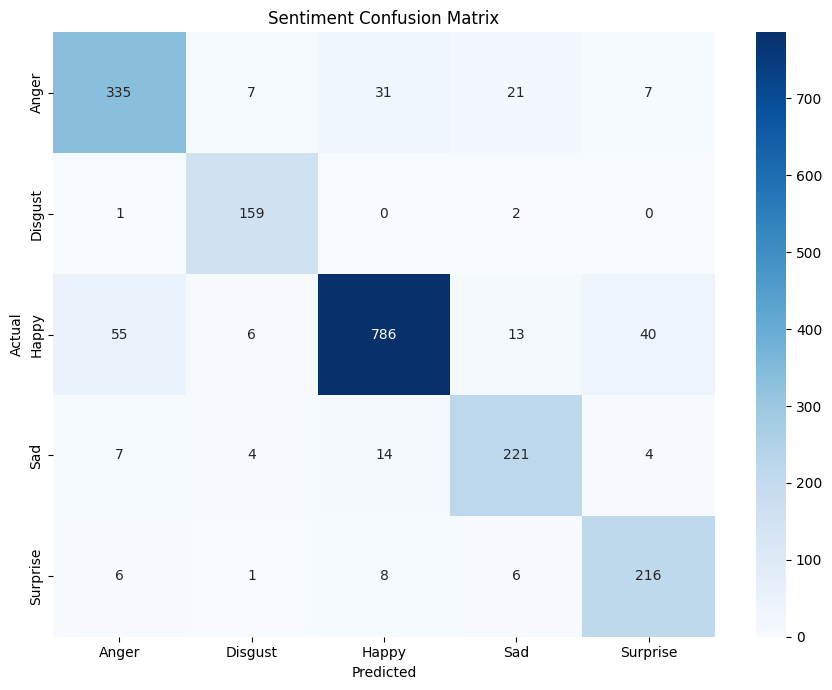

In [ ]:
cm = confusion_matrix(
    sentiment_true,
    sentiment_pred,
    labels=np.arange(
        len(sentiment_encoder.classes_)
    )
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sentiment_encoder.classes_,
    yticklabels=sentiment_encoder.classes_
)

plt.title(
    "Sentiment Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

CELL 50 — Intent Confusion Matrix

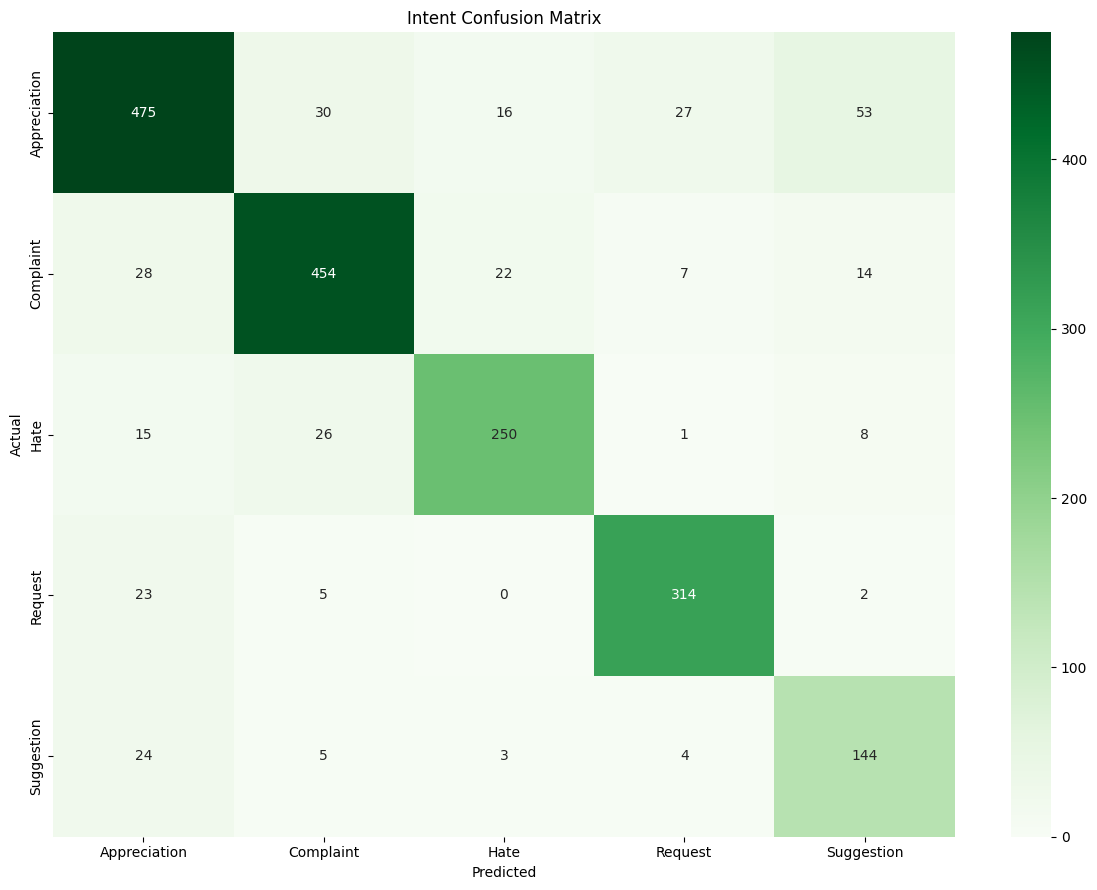

In [ ]:
cm = confusion_matrix(
    intent_true,
    intent_pred,
    labels=np.arange(
        len(intent_encoder.classes_)
    )
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=intent_encoder.classes_,
    yticklabels=intent_encoder.classes_
)

plt.title(
    "Intent Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

CELL 51 — Training vs Validation Loss

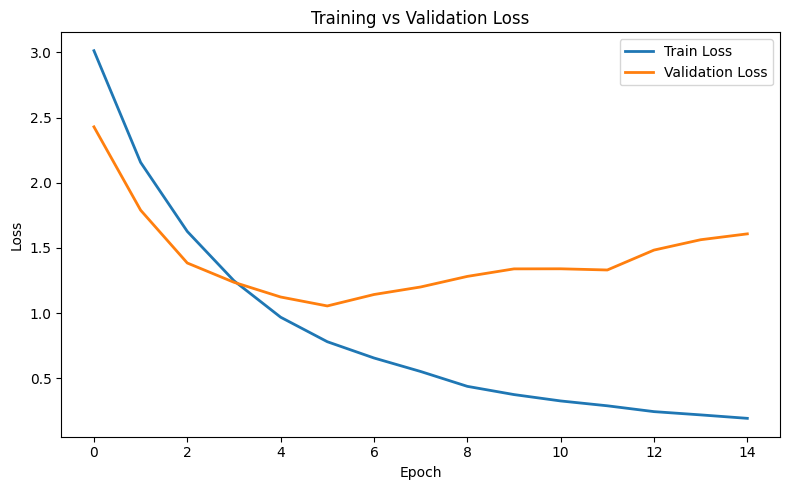

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    label="Train Loss",
    linewidth=2
)

plt.plot(
    history["valid_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training vs Validation Loss"
)

plt.legend()

plt.tight_layout()
plt.show()

CELL 52 — Training vs Validation Macro F1

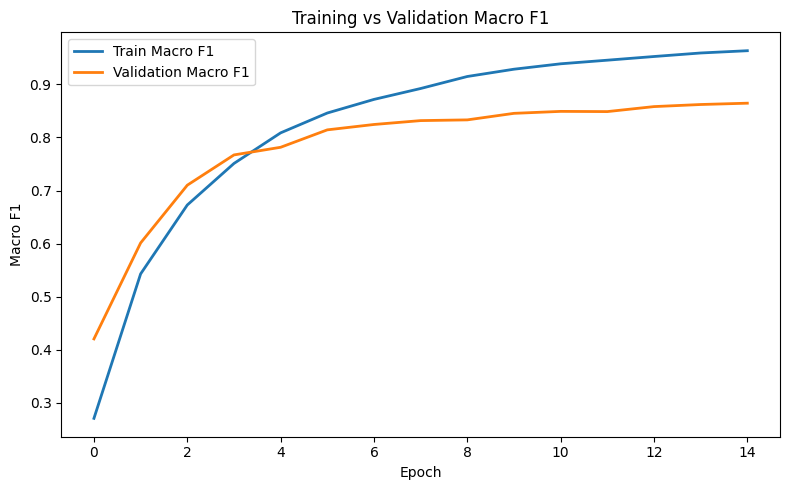

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_macro_f1"],
    label="Train Macro F1",
    linewidth=2
)

plt.plot(
    history["valid_macro_f1"],
    label="Validation Macro F1",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")

plt.title(
    "Training vs Validation Macro F1"
)

plt.legend()

plt.tight_layout()
plt.show()

CELL 53 — Sentiment and Intent F1

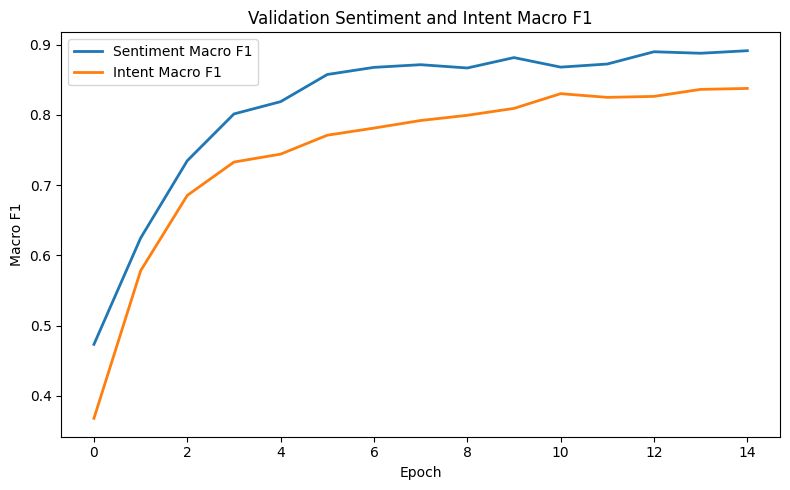

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["sentiment_f1"],
    label="Sentiment Macro F1",
    linewidth=2
)

plt.plot(
    history["intent_f1"],
    label="Intent Macro F1",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")

plt.title(
    "Validation Sentiment and Intent Macro F1"
)

plt.legend()

plt.tight_layout()
plt.show()

CELL 54 — Save Final Model

In [ ]:
torch.save(
    model.state_dict(),
    "final_multitask_muril_sentiment_intent.pt"
)

print(
    "Final Sentiment + Intent MuRIL model saved successfully."
)

Final Sentiment + Intent MuRIL model saved successfully.


CELL 55 — Save Label Encoders

In [ ]:
import joblib

joblib.dump(
    sentiment_encoder,
    "sentiment_encoder.pkl"
)

joblib.dump(
    intent_encoder,
    "intent_encoder.pkl"
)

print("Sentiment encoder saved.")
print("Intent encoder saved.")

Sentiment encoder saved.
Intent encoder saved.


CELL 56 — Prediction Function

In [ ]:
def predict(text):

    original_text = str(text)

    # --------------------------------------------
    # Clean text
    # --------------------------------------------

    cleaned_text = clean_text(
        original_text
    )

    # --------------------------------------------
    # Extract and normalize expressive features
    # Use the same training statistics as the dataset
    # --------------------------------------------

    expressive_values = expressive_features(
        original_text
    ).to_numpy(dtype=np.float32)

    expressive_mean = feature_mean[
        feature_columns
    ].to_numpy(dtype=np.float32)

    expressive_std = feature_std[
        feature_columns
    ].to_numpy(dtype=np.float32)

    expressive_values = (
        expressive_values - expressive_mean
    ) / expressive_std

    expressive = torch.tensor(
        expressive_values,
        dtype=torch.float
    ).unsqueeze(0).to(device)

    # --------------------------------------------
    # Tokenization
    # --------------------------------------------

    encoding = tokenizer(
        cleaned_text,
        max_length=128,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    input_ids = (
        encoding["input_ids"].to(device)
    )

    attention_mask = (
        encoding["attention_mask"].to(device)
    )

    # --------------------------------------------
    # Model prediction
    # --------------------------------------------

    model.eval()

    with torch.no_grad():

        (
            sentiment_logits,
            intent_logits
        ) = model(
            input_ids,
            attention_mask,
            expressive
        )

    # --------------------------------------------
    # Convert predictions to labels
    # --------------------------------------------

    sentiment_index = torch.argmax(
        sentiment_logits,
        dim=1
    ).item()

    intent_index = torch.argmax(
        intent_logits,
        dim=1
    ).item()

    sentiment = sentiment_mapping[
        sentiment_index
    ]

    intent = intent_mapping[
        intent_index
    ]

    # --------------------------------------------
    # Confidence
    # --------------------------------------------

    sentiment_probability = torch.softmax(
        sentiment_logits,
        dim=1
    )

    intent_probability = torch.softmax(
        intent_logits,
        dim=1
    )

    sentiment_confidence = (
        sentiment_probability[0, sentiment_index]
        .item()
    )

    intent_confidence = (
        intent_probability[0, intent_index]
        .item()
    )

    # --------------------------------------------
    # Display
    # --------------------------------------------

    print("=" * 60)
    print("PREDICTION")
    print("=" * 60)

    print("Sentence :", original_text)

    print()
    print(
        f"Sentiment : {sentiment}"
    )

    print(
        f"Sentiment Confidence : "
        f"{sentiment_confidence:.4f}"
    )

    print()
    print(
        f"Intent : {intent}"
    )

    print(
        f"Intent Confidence : "
        f"{intent_confidence:.4f}"
    )

    print("=" * 60)

    return {
        "text": original_text,
        "sentiment": sentiment,
        "sentiment_confidence": sentiment_confidence,
        "intent": intent,
        "intent_confidence": intent_confidence
    }

CELL 57 — Test Prediction

In [ ]:
result = predict(
    "Semma movie da... Vera level acting 🔥"
)

PREDICTION
Sentence : Semma movie da... Vera level acting 🔥

Sentiment : Happy
Sentiment Confidence : 1.0000

Intent : Appreciation
Intent Confidence : 1.0000


CELL 58 — Another Prediction Example

In [ ]:
result = predict(
    "Enakku intha product romba pidichirukku"
)

PREDICTION
Sentence : Enakku intha product romba pidichirukku

Sentiment : Surprise
Sentiment Confidence : 0.9997

Intent : Complaint
Intent Confidence : 0.9712


CELL 59 — Display Final Class Information

In [ ]:
print("=" * 70)
print("FINAL MODEL CONFIGURATION")
print("=" * 70)

print("\nModel:")
print(MODEL_NAME)

print("\nTasks:")
print("1. Sentiment Detection")
print("2. Intent Detection")

print("\nSentiment Classes:")
for i, label in enumerate(
    sentiment_encoder.classes_
):
    print(f"{i}: {label}")

print("\nIntent Classes:")
for i, label in enumerate(
    intent_encoder.classes_
):
    print(f"{i}: {label}")

print("\nDataset:")
print("Training samples   :", len(train_df))
print("Validation samples :", len(valid_df))
print("Testing samples    :", len(test_df))

print("\nFinal Test Metrics:")
print(
    f"Sentiment Macro F1 : {sentiment_f1:.4f}"
)

print(
    f"Intent Macro F1    : {intent_f1:.4f}"
)

print(
    f"Average Macro F1   : {overall_macro_f1:.4f}"
)

FINAL MODEL CONFIGURATION

Model:
google/muril-base-cased

Tasks:
1. Sentiment Detection
2. Intent Detection

Sentiment Classes:
0: Anger
1: Disgust
2: Happy
3: Sad
4: Surprise

Intent Classes:
0: Appreciation
1: Complaint
2: Hate
3: Request
4: Suggestion

Dataset:
Training samples   : 9100
Validation samples : 1950
Testing samples    : 1950

Final Test Metrics:
Sentiment Macro F1 : 0.8786
Intent Macro F1    : 0.8298
Average Macro F1   : 0.8542
